In [381]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import argparse
import os

sns.set_theme()

In [382]:
from scipy.io import loadmat
import h5py, torch

# mat = loadmat('data/NavierStokes_V1e-5_N1200_T20.mat')
# print(mat.keys())
# w = mat['u'].transpose((0, 1, 2, 3))

mat = {}
# f = h5py.File('data/ns_V1e-4_N10000_T30.mat')
f = h5py.File('data/ns_V1e-3_N5000_T50.mat')
for k, v in f.items():
    mat[k] = np.array(v)
print(mat.keys())
print(mat['a'].shape, mat['t'].shape)
w = mat['u'].transpose((3, 1, 2, 0))
w = w[:200]

# mat = np.load('data/KFvorticity_Re100_N50_T500.npy')
# w = mat.transpose((0, 2, 3, 1))

# mat = np.load('data/KFvorticity_Re500_N1000_T500.npy')
# w = mat.transpose((0, 2, 3, 1))[...,:100]

print(w.shape)

dict_keys(['a', 't', 'u'])
(64, 64, 5000) (50, 1)
(200, 64, 64, 50)


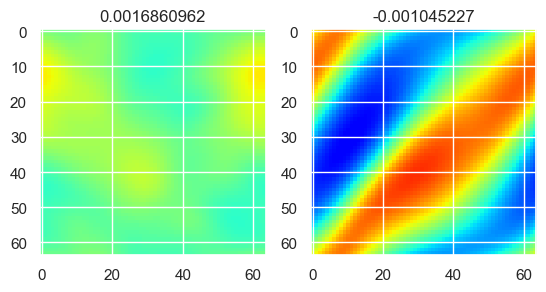

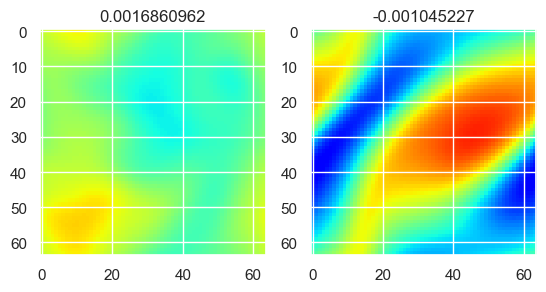

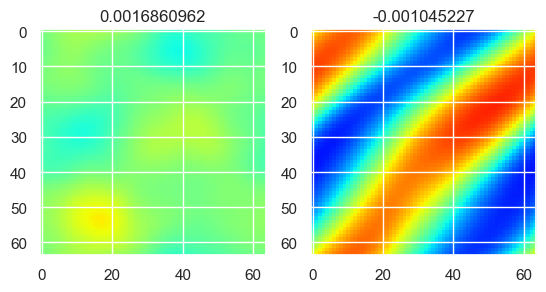

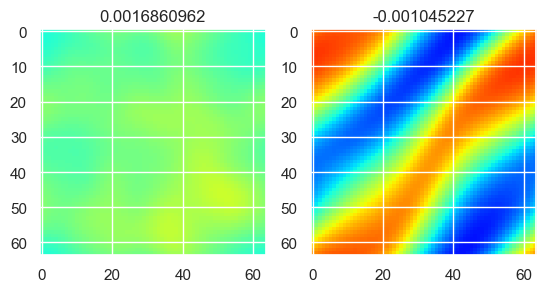

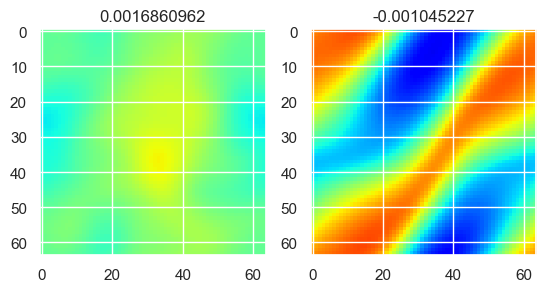

In [383]:
for i in range(5):
    fig, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(w[i, :, :, 0], cmap='jet', vmin=w.min(), vmax=w.max())
    ax1.set_title(str(w[0].sum()))
    ax2.imshow(w[i, :, :, 19], cmap='jet', vmin=w.min(), vmax=w.max())
    ax2.set_title(str(w[1].sum()))
    plt.show()

In [384]:
def vor2vel(w, L=2 * np.pi):
    '''
    Convert vorticity into velocity
    Args:
        w: vorticity with shape (batchsize, num_x, num_y, num_t)

    Returns:
        ux, uy with the same shape
    '''
    batchsize = w.size(0)
    nx = w.size(1)
    ny = w.size(2)
    nt = w.size(3)
    device = w.device
    w = w.reshape(batchsize, nx, ny, nt)

    w_h = torch.fft.fft2(w, dim=[1, 2])
    # Wavenumbers in y-direction
    k_max = nx // 2
    N = nx
    k_x = torch.cat((torch.arange(start=0, end=k_max, step=1, device=device),
                     torch.arange(start=-k_max, end=0, step=1, device=device)), 0) \
        .reshape(N, 1).repeat(1, N).reshape(1, N, N, 1)
    k_y = torch.cat((torch.arange(start=0, end=k_max, step=1, device=device),
                     torch.arange(start=-k_max, end=0, step=1, device=device)), 0) \
        .reshape(1, N).repeat(N, 1).reshape(1, N, N, 1)
    # Negative Laplacian in Fourier space
    lap = (k_x ** 2 + k_y ** 2)
    lap[0, 0, 0, 0] = 1.0
    f_h = w_h / lap

    ux_h = 2 * np.pi / L * 1j * k_y * f_h
    uy_h = -2 * np.pi / L * 1j * k_x * f_h

    ux = torch.fft.irfft2(ux_h[:, :, :k_max + 1], dim=[1, 2])
    uy = torch.fft.irfft2(uy_h[:, :, :k_max + 1], dim=[1, 2])
    return ux, uy

In [385]:
import torch
ux, uy = vor2vel(torch.Tensor(w))
ux = ux.cpu().numpy()
uy = uy.cpu().numpy()
print(ux.shape, uy.shape)

energy = []
for vx, vy in zip(ux, uy):
    energy.append(0.5 * (vx ** 2 + vy ** 2).sum(axis=(0, 1)))
    
energy = np.array(energy)
print(energy, energy.shape)

(200, 64, 64, 50) (200, 64, 64, 50)
[[  83.19774   101.50213   133.23288  ... 1150.3759   1151.9412
  1152.0432  ]
 [ 242.6902    242.3677    257.00934  ... 1149.367    1151.2797
  1149.6569  ]
 [  50.93798    80.052895  120.7303   ... 1217.0532   1208.5021
  1203.377   ]
 ...
 [  56.40721    82.35616   120.28795  ... 1193.5941   1185.3792
  1174.9844  ]
 [ 107.33024   131.85788   167.49422  ... 1136.1993   1132.3777
  1133.2139  ]
 [  88.06366   112.80178   149.74434  ... 1136.7366   1132.731
  1133.2432  ]] (200, 50)


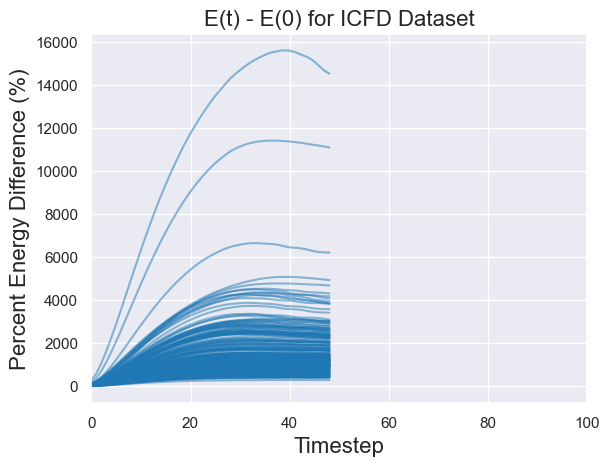

In [386]:
differences = (energy[:, 1:] - energy[:, :1]) / energy[:, 0:1] * 100

for i in range(len(energy)):
    plt.plot(differences[i], color = 'tab:blue', alpha=0.5)

plt.title('E(t) - E(0) for ICFD Dataset', fontsize=16)
plt.xlabel('Timestep', fontsize=16)
plt.ylabel('Percent Energy Difference (%)', fontsize=16)

plt.xlim(0, 100)

plt.savefig('incompressible_energy_difference.png')

plt.show()

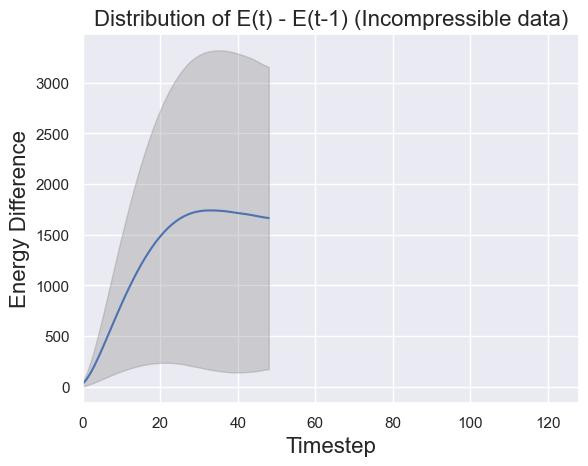

In [387]:
plt.plot(np.arange(differences.shape[1]), differences.mean(axis=0))
plt.fill_between(np.arange(differences.shape[1]),
                 differences.mean(axis=0) - differences.std(axis=0),
                 differences.mean(axis=0) + differences.std(axis=0), color='gray', alpha=0.3)

plt.title('Distribution of E(t) - E(t-1) (Incompressible data)', fontsize=16)
plt.xlabel('Timestep', fontsize=16)
plt.ylabel('Energy Difference', fontsize=16)

plt.xlim(0, 128)

# plt.savefig('incompressible_energy_difference.png')

plt.show()

In [388]:
# def forcing(S, device):
#     x = torch.tensor(np.linspace(0, 2*np.pi, S, endpoint=False), dtype=torch.float, device=device).reshape(1, S).repeat(S, 1)
#     return -4 * (torch.cos(4*(x))).reshape(1,S,S,1)

def forcing(S, device):
    x1 = torch.tensor(np.linspace(0, 1, S, endpoint=False), dtype=torch.float, device=device).reshape(1, S).repeat(S, 1)
    x2 = torch.tensor(np.linspace(0, 1, S, endpoint=False), dtype=torch.float, device=device).reshape(S, 1).repeat(1, S)
    x = x1 + x2
    return (0.1 * (torch.sin(2 * np.pi * x) + torch.cos(2 * np.pi * x))).reshape(1, S, S, 1)

def pde_iCFD2d_vorticity(w, v=1e-3, t_interval=1.0):
    batchsize = w.size(0)
    nx = w.size(1)
    ny = w.size(2)
    nt = w.size(3)
    device = w.device
 
    w_h = torch.fft.fft2(w, dim=[1, 2])
    # Wavenumbers in y-direction
    k_max = nx//2
    N = nx
    k_x = torch.cat((torch.arange(start=0, end=k_max, step=1, device=device),
                     torch.arange(start=-k_max, end=0, step=1, device=device)), 0).reshape(N, 1).repeat(1, N).reshape(1,N,N,1)
    k_y = torch.cat((torch.arange(start=0, end=k_max, step=1, device=device),
                     torch.arange(start=-k_max, end=0, step=1, device=device)), 0).reshape(1, N).repeat(N, 1).reshape(1,N,N,1)
    # Negative Laplacian in Fourier space
    lap = (k_x ** 2 + k_y ** 2)
    lap[0, 0, 0] = 1.0
    f_h = w_h / lap

    ux_h = 1j * k_y * f_h
    uy_h = -1j * k_x * f_h
    wx_h = 1j * k_x * w_h
    wy_h = 1j * k_y * w_h
    wlap_h = -lap * w_h

    ux = torch.fft.irfft2(ux_h[:, :, :k_max + 1], dim=[1, 2])
    uy = torch.fft.irfft2(uy_h[:, :, :k_max + 1], dim=[1, 2])
    wx = torch.fft.irfft2(wx_h[:, :, :k_max + 1], dim=[1,2])
    wy = torch.fft.irfft2(wy_h[:, :, :k_max + 1], dim=[1,2])
    wlap = torch.fft.irfft2(wlap_h[:, :, :k_max + 1], dim=[1,2])

    dt = 1 #t_interval / (nt-1)
    wt = (w[:, :, :, 2:] - w[:, :, :, :-2]) / (2 * dt)
    
    f = forcing(nx, device)
    residual = wt + (ux*wx + uy*wy - v*wlap)[..., 1:-1] - f
    return residual
    # return torch.mean(residual)


In [389]:
print(w.shape)
wt = torch.from_numpy(w)
losses = pde_iCFD2d_vorticity(wt).cpu().numpy()

print(losses.shape)
# print(losses.mean(axis=(1,2)))
# print(losses.std(axis=(1,2)))print(w.shape)

(200, 64, 64, 50)
(200, 64, 64, 48)


6.3795597e-10
1.0244548e-10


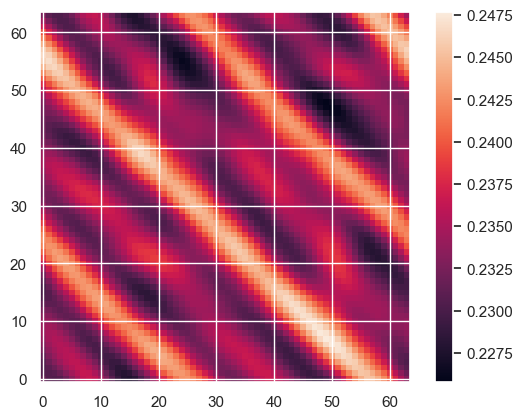

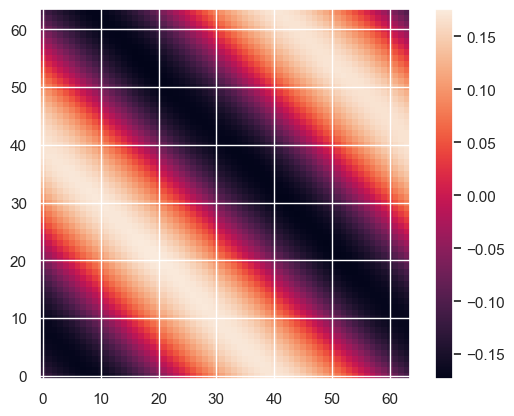

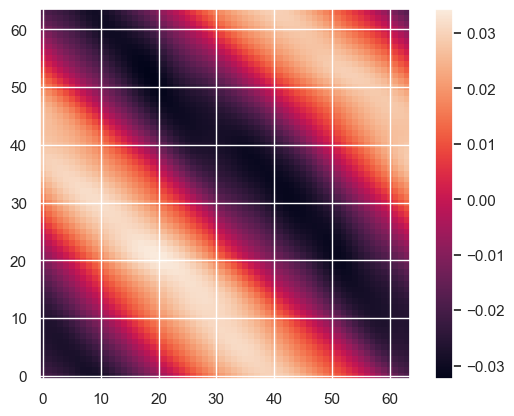

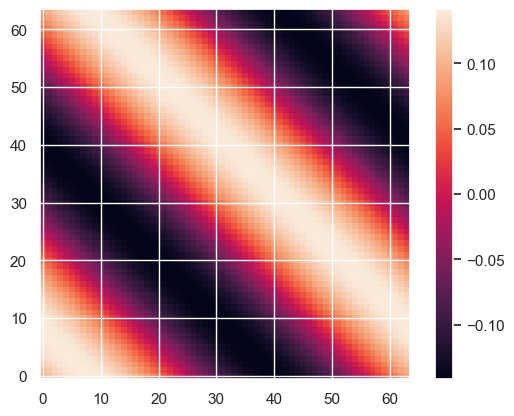

In [390]:
f = forcing(64, 'cpu').numpy()
print(losses.mean())
loss_f = losses + f
print(loss_f.mean())
term = loss_f - f 

plt.imshow(abs(term).mean(axis=(0,3)), origin='lower')
plt.colorbar()
plt.show()

plt.imshow(term.mean(axis=(0,3)), origin='lower')
plt.colorbar()
plt.show()

plt.imshow(loss_f.mean(axis=(0,3)), origin='lower')
plt.colorbar()
plt.show()

plt.imshow(forcing(64, 'cpu').squeeze(), origin='lower')
plt.colorbar()
plt.show()


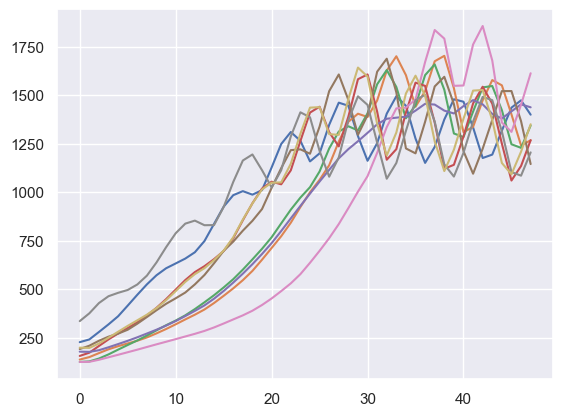

In [391]:

loss_by_time = abs(losses).sum(axis=(1, 2))
for i in range(1, 10):
    plt.plot(loss_by_time[i])
plt.show()